# 04 · Error analysis and the final model

All diagnostics use **cross-fitted predictions**: each record's out-of-fold probability averaged over
the ten repeats, so no prediction comes from a model that saw that record. The label is the proxy
`High_Admission_Chance` at target threshold 0.75 (the dataset's estimated Chance of Admit at or above
0.75), and predictions use the 0.50 classifier threshold. Nothing here concerns real admission
decisions.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "gradmit").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40, "display.width", 200, "display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
TEAL, OCHRE, SLATE, BRICK = "#0B6E69", "#B7791F", "#6B7C80", "#B4452F"

import joblib
from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_recall_curve, roc_curve

from gradmit.data import (ARTIFACTS_DIR, CLASSIFIER_THRESHOLD, DEFAULT_TARGET_THRESHOLD, FEATURES,
                          SCORE_COLUMN, load_data, make_target)
from gradmit.modelling import positive_probability, rebuild_pipeline, train_final
from gradmit.reporting import cross_fitted_summary, error_frame, error_slices, load_outputs, oof_for
from gradmit.verification import load_artifact

THR = DEFAULT_TARGET_THRESHOLD
df = load_data()
outputs = load_outputs()
selected = outputs["evaluation"]["selected_model"]
rows = oof_for(outputs["oof"], THR, selected)
y_true, prob, pred = rows.y_true.to_numpy(), rows.mean_oof_prob.to_numpy(), rows.pred.to_numpy()
print(selected, "| records:", len(rows))

Logistic Regression | records: 500


## Cross-fitted confusion matrix

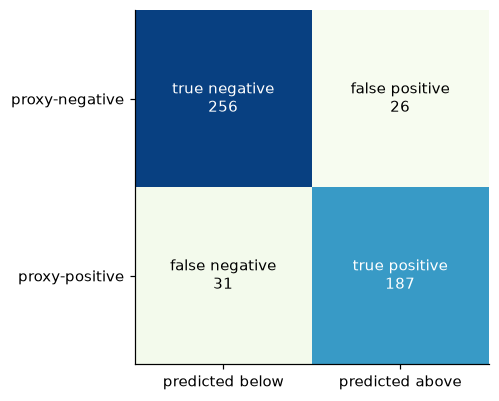

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,brier
cross-fitted metric,0.886,0.883,0.878,0.858,0.868,0.96,0.081


In [2]:
summary = cross_fitted_summary(outputs["oof"], THR, selected)
assert summary == outputs["evaluation"]["thresholds"][f"{THR:.2f}"]["cross_fitted"]
cm = summary["confusion_matrix"]
matrix = np.array([[cm["tn"], cm["fp"]], [cm["fn"], cm["tp"]]])
fig, ax = plt.subplots(figsize=(4.4, 3.8))
ax.imshow(matrix, cmap="GnBu"); ax.grid(False)
names = [["true negative", "false positive"], ["false negative", "true positive"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{names[i][j]}\n{matrix[i, j]}", ha="center", va="center",
                color="white" if matrix[i, j] > matrix.max() / 2 else "black")
ax.set_xticks([0, 1], ["predicted below", "predicted above"]); ax.set_yticks([0, 1], ["proxy-negative", "proxy-positive"])
plt.tight_layout(); plt.show()
pd.Series(summary["metrics"], name="cross-fitted metric").to_frame().T

## Calibration, ROC and precision-recall

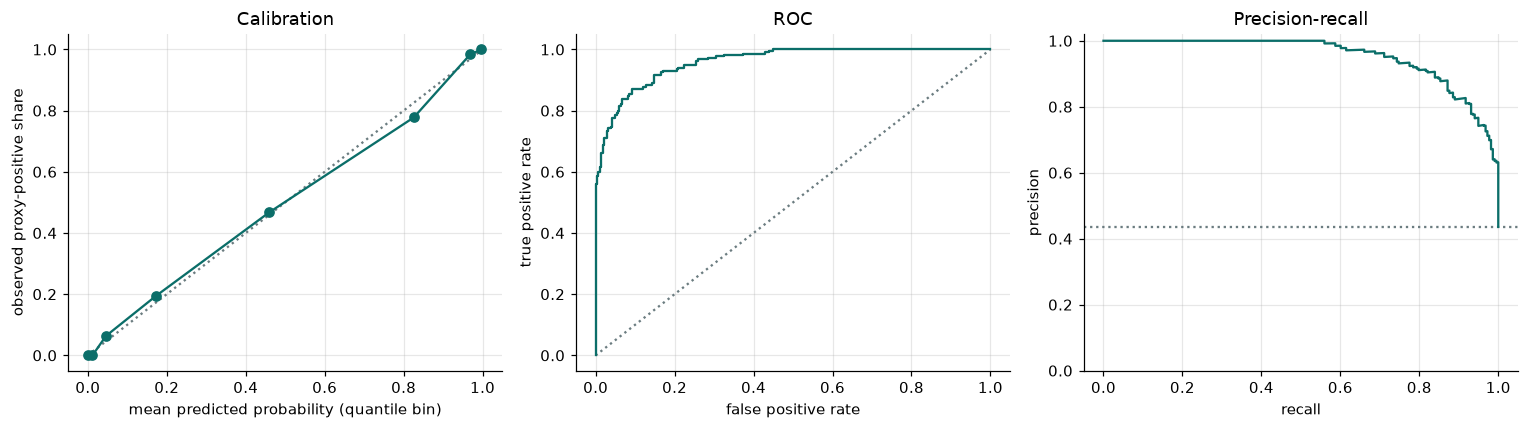

**Reading the curves.** Cross-fitted ROC-AUC is 0.960 and the Brier score is 0.081. The largest gap between predicted and observed share across the eight quantile bins is 0.048. The probabilities are the fitted model's own, with no extra calibration step, so this curve is the evidence for how far they can be read as probabilities of the proxy label.

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
frac, mean_pred = calibration_curve(y_true, prob, n_bins=8, strategy="quantile")
axes[0].plot([0, 1], [0, 1], ls=":", color=SLATE); axes[0].plot(mean_pred, frac, "o-", color=TEAL)
axes[0].set(xlabel="mean predicted probability (quantile bin)", ylabel="observed proxy-positive share", title="Calibration")
fpr, tpr, _ = roc_curve(y_true, prob)
axes[1].plot([0, 1], [0, 1], ls=":", color=SLATE); axes[1].plot(fpr, tpr, color=TEAL)
axes[1].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC")
precision, recall, _ = precision_recall_curve(y_true, prob)
axes[2].axhline(y_true.mean(), ls=":", color=SLATE); axes[2].plot(recall, precision, color=TEAL)
axes[2].set(xlabel="recall", ylabel="precision", title="Precision-recall", ylim=(0, 1.02))
plt.tight_layout(); plt.show()

gap = float(np.abs(frac - mean_pred).max())
m = summary["metrics"]
display(Markdown(
    f"**Reading the curves.** Cross-fitted ROC-AUC is {m['roc_auc']:.3f} and the Brier score is {m['brier']:.3f}. "
    f"The largest gap between predicted and observed share across the eight quantile bins is {gap:.3f}. "
    "The probabilities are the fitted model's own, with no extra calibration step, so this curve is the evidence "
    "for how far they can be read as probabilities of the proxy label."))

## Where the errors are

In [4]:
errors = error_frame(df, outputs["oof"], THR, selected)
slices = error_slices(errors, THR)
display(slices.style.format({"error_rate": "{:.1%}"}).hide(axis="index"))

gap_slice = slices[slices["slice"] == "Gap to target threshold"].set_index("value")
near, far = gap_slice.loc["Within 0.05"], gap_slice.loc["More than 0.05"]
display(Markdown(
    f"**Errors concentrate at the cut.** {int(errors.error.sum())} of {len(errors)} cross-fitted predictions are wrong. "
    f"Among the {int(near.n)} records whose Chance of Admit is within 0.05 of the target threshold the error rate is "
    f"{near.error_rate:.1%}; among the other {int(far.n)} it is {far.error_rate:.1%}. Most errors are records the "
    "label itself places almost arbitrarily."))

slice,value,n,errors,error_rate
Gap to target threshold,More than 0.05,342,11,3.2%
Gap to target threshold,Within 0.05,158,46,29.1%
Research status,Has research,280,34,12.1%
Research status,No research,220,23,10.5%
CGPA band,8.0-8.5,140,13,9.3%
CGPA band,8.5-9.0,128,37,28.9%
CGPA band,< 8.0,93,1,1.1%
CGPA band,> 9.0,139,6,4.3%
University rating,1,34,1,2.9%
University rating,2,126,8,6.3%


**Errors concentrate at the cut.** 57 of 500 cross-fitted predictions are wrong. Among the 158 records whose Chance of Admit is within 0.05 of the target threshold the error rate is 29.1%; among the other 342 it is 3.2%. Most errors are records the label itself places almost arbitrarily.

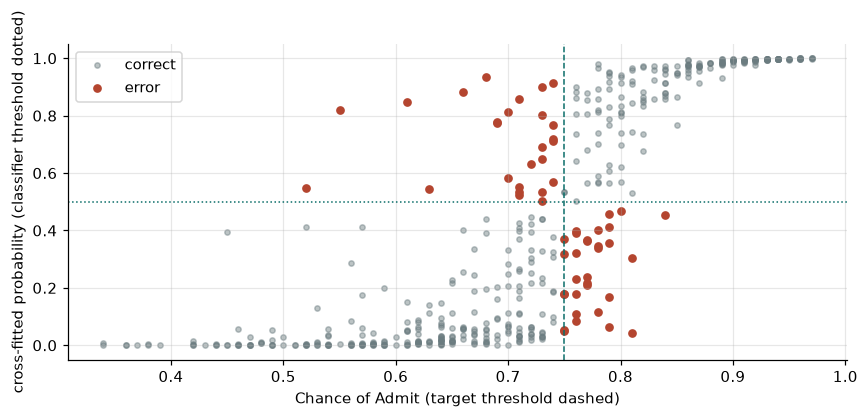

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ok = errors[~errors.error]; bad = errors[errors.error]
ax.scatter(ok[SCORE_COLUMN], ok.mean_oof_prob, s=12, color=SLATE, alpha=0.45, label="correct")
ax.scatter(bad[SCORE_COLUMN], bad.mean_oof_prob, s=22, color=BRICK, label="error")
ax.axvline(THR, color=TEAL, ls="--", lw=1); ax.axhline(CLASSIFIER_THRESHOLD, color=TEAL, ls=":", lw=1)
ax.set(xlabel="Chance of Admit (target threshold dashed)", ylabel="cross-fitted probability (classifier threshold dotted)")
ax.legend(); plt.tight_layout(); plt.show()

## Most confident errors

In [6]:
worst = errors[errors.error].sort_values("confidence", ascending=False).head(10)
worst[["error_type", "mean_oof_prob", SCORE_COLUMN, "distance_to_threshold"] + FEATURES].style.format(precision=2).hide(axis="index")

error_type,mean_oof_prob,Chance_of_Admit,distance_to_threshold,GRE_Score,TOEFL_Score,University_Rating,SOP,LOR,CGPA,Research
False negative,0.04,0.81,0.06,321,107,2,2.00,1.50,8.44,0
False negative,0.05,0.75,0.00,308,106,3,3.50,2.50,8.21,1
False negative,0.05,0.75,0.00,315,105,3,2.00,2.50,8.48,0
False negative,0.06,0.79,0.04,311,106,2,3.50,3.00,8.26,1
False positive,0.93,0.68,-0.07,318,109,3,3.50,4.00,9.22,1
False negative,0.08,0.76,0.01,313,98,3,2.50,4.50,8.30,1
False positive,0.91,0.74,-0.01,326,112,3,3.50,3.00,9.05,1
False positive,0.90,0.73,-0.02,322,112,4,3.50,2.50,9.02,1
False negative,0.11,0.76,0.01,309,99,3,4.00,4.00,8.56,0
False negative,0.12,0.78,0.03,307,107,2,3.00,3.50,8.52,1


In [7]:
display(Markdown(
    f"**Reading the table.** The ten most confident errors have Chance of Admit between {worst[SCORE_COLUMN].min():.2f} "
    f"and {worst[SCORE_COLUMN].max():.2f}; their median distance from the {THR:.2f} threshold is "
    f"{worst.distance_to_threshold.abs().median():.2f}. "
    f"{int((worst.error_type == 'False negative').sum())} are false negatives and "
    f"{int((worst.error_type == 'False positive').sum())} false positives. These are profiles whose seven features "
    "point one way while the dataset's score falls on the other side of the cut."))

**Reading the table.** The ten most confident errors have Chance of Admit between 0.68 and 0.81; their median distance from the 0.75 threshold is 0.01. 7 are false negatives and 3 false positives. These are profiles whose seven features point one way while the dataset's score falls on the other side of the cut.

## Final model

The selected family is tuned with the inner cross-validation on all 500 records and refitted on all
of them, exactly as `scripts/train_final_model.py` does. In-sample numbers are used only to check the
artifact, never as performance estimates.

In [8]:
pipeline, params, inner_score = train_final(df, selected, THR)
print("tuned hyperparameters:", params, "| inner-CV balanced accuracy:", round(inner_score, 4))

steps = pipeline.named_steps
if hasattr(steps["model"], "coef_"):
    coefs = pd.Series(steps["model"].coef_[0], index=FEATURES, name="standardised coefficient (log-odds per SD)")
    display(coefs.sort_values(ascending=False).to_frame().style.format(precision=3))
    display(Markdown("Coefficients describe how the fitted model combines correlated features to reproduce the "
                     "proxy label. They are not effects of changing a feature."))

tuned hyperparameters: {'model__C': 10.0} | inner-CV balanced accuracy: 0.8766


,standardised coefficient (log-odds per SD)
CGPA,2.346
GRE_Score,0.733
TOEFL_Score,0.511
SOP,0.387
University_Rating,0.364
Research,0.355
LOR,0.299


Coefficients describe how the fitted model combines correlated features to reproduce the proxy label. They are not effects of changing a feature.

## Artifact parity

In [9]:
artifact, meta = load_artifact()
saved = positive_probability(artifact, df[FEATURES])
fresh = positive_probability(pipeline, df[FEATURES])
rebuilt = rebuild_pipeline(meta["model_name"], meta["best_params"]).fit(df[FEATURES], make_target(df, THR).to_numpy())

assert meta["model_name"] == selected and meta["best_params"] == params
assert np.allclose(saved, fresh, atol=1e-6)
assert np.allclose(saved, positive_probability(rebuilt, df[FEATURES]), atol=1e-6)
assert np.allclose(saved[:5], meta["parity"]["first_rows_probability"], atol=1e-6)
assert int((saved >= CLASSIFIER_THRESHOLD).sum()) == meta["parity"]["n_predicted_positive"]
print(f"artifacts/gradmit_pipeline.joblib reproduces a fresh fit: largest probability difference "
      f"{np.abs(saved - fresh).max():.1e} over {len(df)} records")
pd.Series({k: meta[k] for k in ["model_name", "target_threshold", "classifier_threshold", "best_params",
                                 "n_training_rows", "n_training_positive", "scikit_learn_version"]}, name="model_metadata.json").to_frame()

artifacts/gradmit_pipeline.joblib reproduces a fresh fit: largest probability difference 0.0e+00 over 500 records


,model_metadata.json
model_name,Logistic Regression
target_threshold,0.75
classifier_threshold,0.5
best_params,{'model__C': 10.0}
n_training_rows,500
n_training_positive,218
scikit_learn_version,1.9.1


## Limitations

- The label is derived from an estimated score; none of this is validated against admission decisions.
- Errors cluster where the label is least meaningful, so headline accuracy partly measures how many
  records happen to lie near the cut.
- 500 records from one source: the estimates describe this dataset, not applicants in general.
- The app's predictor inherits all of the above and warns when an input lies outside the training range.